# Exploration: the outcome, its family, correlations and PCA


**Question.** Does a shot-quality model need to know who took the shot? This notebook looks at the data before any model: the outcome and its family, which columns move together, and how many principal components hold 90% of the variation. One row is one WNBA 2025 shot. Seed 651.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../shots_with_bios.csv")
y = df["made_flag"]
print("rows, columns:", df.shape)
print("make rate:", round(y.mean(), 4))

rows, columns: (38535, 25)
make rate: 0.4392


## 1. The outcome

`made_flag` is 1 for a made shot and 0 for a miss. Left: how many of each. Right: the make rate by shot distance, since distance is the strongest column I expect to use.

,mean,count
shot_distance,,
0,0.727069,1341
1,0.679021,2779
2,0.618049,3435
3,0.549098,2994
4,0.444184,2132
5,0.417062,1688
6,0.379637,1267
7,0.350402,996
8,0.372981,681


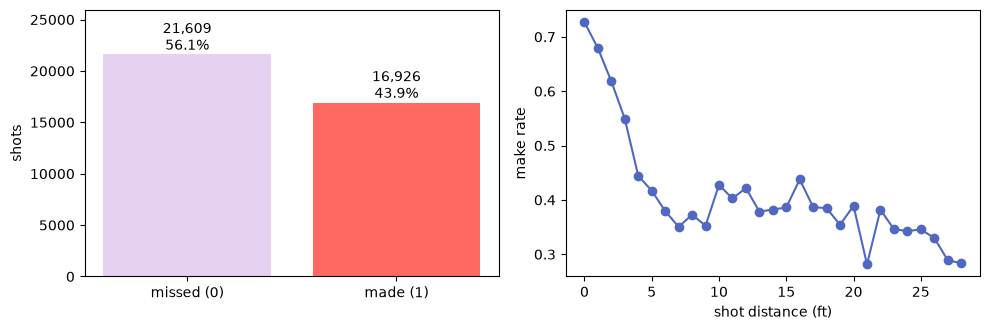

distances with at least 100 shots: 29


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
counts = y.value_counts().sort_index()
ax[0].bar(["missed (0)", "made (1)"], counts.values, color=["#E6D1F2", "#FF6961"])
for i, c in enumerate(counts.values):
    ax[0].text(i, c, f"{c:,}\n{c/len(y):.1%}", ha="center", va="bottom")
ax[0].set_ylim(0, counts.max() * 1.2); ax[0].set_ylabel("shots")
by = df.groupby("shot_distance")["made_flag"].agg(["mean", "count"])
by = by[by["count"] >= 100]                 # keep distances with at least 100 shots
display(by)
ax[1].plot(by.index, by["mean"], "o-", color="#5168C0")
ax[1].set_xlabel("shot distance (ft)"); ax[1].set_ylabel("make rate")
plt.tight_layout(); plt.show()
print("distances with at least 100 shots:", len(by))

## 2. The family: why Bernoulli

Each row has exactly two outcomes, made or missed, so one shot is Bernoulli(p). The check below uses the mean and the variance, then I ask whether a single p fits every shooter.

| Family | Why it does not fit `made_flag` |
|---|---|
| Normal | Spreads over every real number; `made_flag` is only 0 or 1, and its variance is tied to its mean. |
| Poisson | Counts with no upper limit and variance equal to the mean. One shot cannot exceed 1, and the variance is far below the mean (check below). |
| Binomial | Counts makes out of n shots. It fits per player or per game, but my unit is one shot, and Binomial(1, p) is Bernoulli. |
| Geometric, negative binomial | Count shots until a make. That is a different question from whether this shot goes in. |
| Exponential, Gamma | Positive continuous values such as waiting times. The outcome is not continuous. |
| Beta | Lives on [0, 1], but it describes a probability, not a 0/1 result.|

In [3]:
p = y.mean()
print("values in made_flag:", [int(v) for v in sorted(y.unique())])
print("mean:", round(y.mean(), 4))
print("variance:", round(y.var(ddof=0), 4), " p(1-p):", round(p * (1 - p), 4))
print("variance / mean:", round(y.var(ddof=0) / y.mean(), 2), " (Poisson needs 1)")

values in made_flag: [0, 1]
mean: 0.4392
variance: 0.2463  p(1-p): 0.2463
variance / mean: 0.56  (Poisson needs 1)


A Poisson would need variance divided by mean to be about 1. Here it is about 0.56, so Poisson is rejected. The variance matches p(1-p), as Bernoulli requires.

**NOTE:** Bernoulli with one common p also assumes every shot has the same chance. Below I compare each player's make rate with what a common p predicts, for players with at least 100 shots.

In [4]:
g = df.groupby("player_id")["made_flag"].agg(["mean", "count"])
g = g[g["count"] >= 100]
expected_sd = np.sqrt(p * (1 - p) / g["count"])     # spread of a rate if every shot had the same p
z = (g["mean"] - p) / expected_sd
print("players with 100+ shots:", len(g))
print("SD of player make rates:", round(g["mean"].std(), 4))
print("SD expected under one common p:", round(expected_sd.mean(), 4))
print("SD of the z-scores (1 if one common p):", round(z.std(), 2))

players with 100+ shots: 122
SD of player make rates: 0.0615
SD expected under one common p: 0.0315
SD of the z-scores (1 if one common p): 2.06


Player make rates vary about twice as much as one common p allows. So the honest family is Bernoulli(p_i) for each shot, with p_i depending on the shot and the shooter. Rows from one player are also not independent.

## 3. Correlation matrix

I use the numeric columns only. IDs and the outcome are not predictors. Height and weight come from the bios, so about 6,600 shots lack a weight (and 332 lack a height); pandas uses the rows that have both columns in each pair.

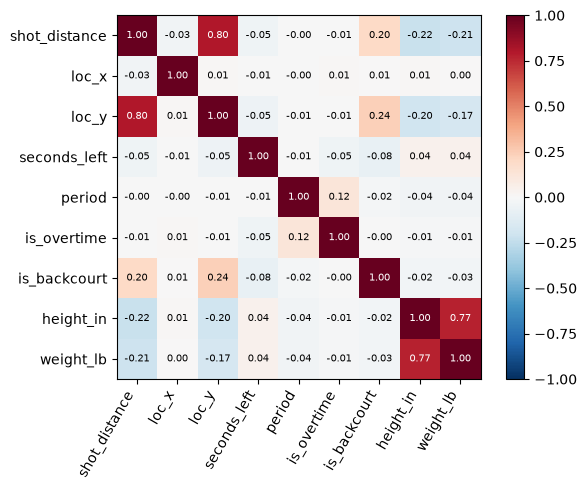

In [5]:
num = ["shot_distance", "loc_x", "loc_y", "seconds_left", "period",
       "is_overtime", "is_backcourt", "height_in", "weight_lb"]
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

In [6]:
print("pairs with |r| above 0.8:")
for i, a in enumerate(num):
    for b in num[i + 1:]:
        if abs(corr.loc[a, b]) > 0.8:
            print(" ", a, "and", b, round(corr.loc[a, b], 4))
print("closest miss: height_in and weight_lb", round(corr.loc["height_in", "weight_lb"], 3))

pairs with |r| above 0.8:
  shot_distance and loc_y 0.8005
closest miss: height_in and weight_lb 0.772


**Decision:** `shot_distance` and `loc_y` are correlated at 0.8005. Shot distance is how far from the basket, and `loc_y` is how far up the court, so they nearly say the same thing for most shots. I keep `shot_distance` because it is what a coach would read, and drop `loc_y`. Height and weight are at 0.77, just under 0.8, so I keep both in view; because weight is missing for many shots I plan to use height only.

## 4. PCA: how many components for 90%

PCA finds new directions that hold the variation. I standardize every column first, so no column wins just by having big units, and I use only the shots that have every column.

shots used: 31969  columns: 9
share of variance: [0.251 0.161 0.126 0.113 0.111 0.097 0.096 0.025 0.021]
cumulative: [0.251 0.412 0.538 0.651 0.761 0.858 0.954 0.979 1.   ]
components needed for 90%: 7


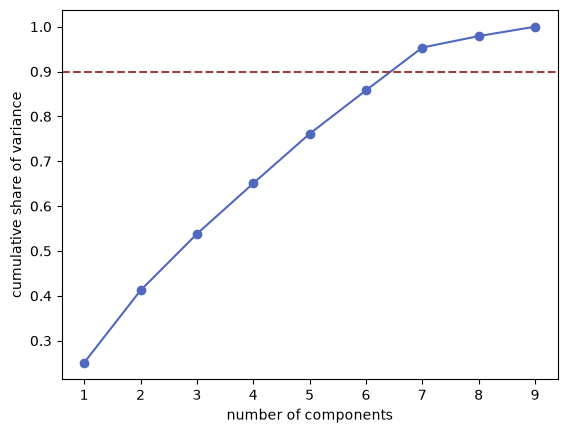

In [7]:
X = df[num].dropna()
Z = (X - X.mean()) / X.std()
eigvals = np.sort(np.linalg.eigvalsh(np.corrcoef(Z.T)))[::-1]
share = eigvals / eigvals.sum()
cum = np.cumsum(share)
k90 = int(np.argmax(cum >= 0.90)) + 1
print("shots used:", len(X), " columns:", len(num))
print("share of variance:", np.round(share, 3))
print("cumulative:", np.round(cum, 3))
print("components needed for 90%:", k90)
plt.plot(range(1, len(cum) + 1), cum, "o-", color="#5168C0")
plt.axhline(0.9, ls="--", color="#9D3F37")
plt.xlabel("number of components"); plt.ylabel("cumulative share of variance")
plt.xticks(range(1, len(cum) + 1)); plt.show()

It takes **7 of the 9** components to reach 90%. PCA barely compresses these columns, because most of them are not related to each other. Only the two redundant pairs from the correlation matrix (distance with `loc_y`, height with weight) show up as the two smallest components. So I will not replace my columns with components; I will drop the redundant ones by name.

## AI Note

I used Claude (Anthropic) to help me write and check this code. I ran every cell on my own laptop and I can explain every line. The words and every interpretation of a number are my own. I made the decision to drop `loc_y` and `weight_lb`.